## TIME SERIES ANALYSIS

In [1]:
# ! pip install sktime

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sktime.utils.plotting import plot_series
from sktime.transformations.series.impute import Imputer
from sklearn.preprocessing import MultiLabelBinarizer

## Esplorazione

In [3]:
df = pd.read_csv('../../dm2_dataset_2425_imdb/imdb_ts.csv', index_col=0)

In [4]:
df

,0,1,2,3,4,5,6,7,8,9,...,93,94,95,96,97,98,99,rating,genre,rating_category
id,,,,,,,,,,,,,,,,,,,,,
tt0062622,57057.0,65469.0,71642.0,73025.0,74060.0,49472.0,30258.0,28036.0,25824.0,32571.0,...,10709.0,11042.0,11388.0,11847.0,12404.0,13679.0,15056.0,8.3,"['Adventure', 'Sci-Fi']",High
tt0064816,1923.0,2422.0,2853.0,2947.0,3054.0,2844.0,2617.0,1998.0,1277.0,1449.0,...,637.0,734.0,857.0,785.0,724.0,713.0,699.0,7.1,"['Crime', 'Drama', 'Romance']",High
tt0088178,332925.0,302503.0,267264.0,261879.0,256608.0,196530.0,112728.0,117384.0,123024.0,119608.0,...,6784.0,7253.0,7776.0,9632.0,11212.0,9010.0,6431.0,8.7,"['Documentary', 'Music']",High
tt0145487,682857.0,407032.0,78058.0,81732.0,86772.0,83724.0,79940.0,39656.0,6974.0,7697.0,...,21094.0,10995.0,1586.0,1421.0,1177.0,970.0,802.0,7.4,"['Action', 'Adventure', 'Sci-Fi']",High
tt0359950,7813372.0,6274563.0,4781588.0,4655046.0,4535301.0,4650574.0,4758452.0,4069428.0,3471755.0,3108057.0,...,88635.0,68347.0,45367.0,28915.0,15494.0,16155.0,16853.0,7.3,"['Adventure', 'Comedy', 'Drama']",High
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
tt9731534,1077363.0,1061148.0,1043451.0,912840.0,738595.0,508118.0,296236.0,318113.0,341113.0,310422.0,...,2396.0,2425.0,2461.0,2223.0,1920.0,1991.0,2051.0,6.4,"['Horror', 'Mystery', 'Thriller']",Medium
tt9735462,56775.0,57750.0,58828.0,53549.0,48484.0,37340.0,19243.0,30804.0,55897.0,40874.0,...,739.0,618.0,488.0,636.0,883.0,904.0,920.0,6.3,"['Biography', 'Comedy', 'Drama']",Medium
tt9764362,3595005.0,3401235.0,3221227.0,2645775.0,2188725.0,1681250.0,1030698.0,1138724.0,1290788.0,1204996.0,...,345246.0,257388.0,182883.0,165311.0,144119.0,128009.0,111756.0,7.2,"['Comedy', 'Horror', 'Thriller']",High


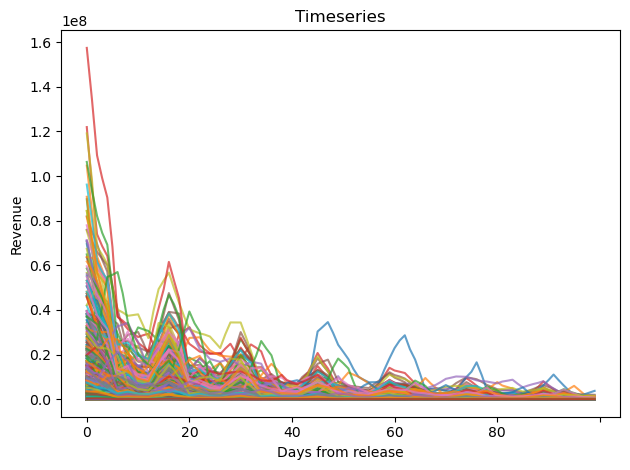

In [5]:
# Per osservare le time series necessario considerare solo valori numerici
df.iloc[:, :100].T.plot(legend=False, alpha=0.7)
plt.title('Timeseries')
plt.xlabel('Days from release')
plt.ylabel('Revenue')
plt.tight_layout()
plt.show()

In [6]:
df.shape

(1134, 103)

In [7]:
df.index

Index(['tt0062622', 'tt0064816', 'tt0088178', 'tt0145487', 'tt0359950',
       'tt0369610', 'tt0435651', 'tt0437086', 'tt0439572', 'tt0448115',
       ...
       'tt9603212', 'tt9620288', 'tt9620292', 'tt9663764', 'tt9682428',
       'tt9731534', 'tt9735462', 'tt9764362', 'tt9784798', 'tt9883996'],
      dtype='object', name='id', length=1134)

In [8]:
df.describe()

,0,1,2,3,4,5,6,7,8,9,...,91,92,93,94,95,96,97,98,99,rating
count,1.134000e+03,1.134000e+03,1.134000e+03,1.134000e+03,1.134000e+03,1.134000e+03,1.134000e+03,1.134000e+03,1.134000e+03,1.134000e+03,...,1.134000e+03,1.134000e+03,1.134000e+03,1.134000e+03,1.134000e+03,1.134000e+03,1.134000e+03,1.134000e+03,1.134000e+03,1134.000000
mean,9.075217e+06,8.521398e+06,7.954433e+06,7.080579e+06,6.200350e+06,4.567772e+06,2.943717e+06,2.932913e+06,2.929824e+06,2.503033e+06,...,3.173743e+05,2.546920e+05,1.909471e+05,1.804780e+05,1.711978e+05,1.457827e+05,1.192445e+05,1.153249e+05,1.111532e+05,6.584921
std,1.559543e+07,1.366932e+07,1.188300e+07,1.066701e+07,9.596818e+06,7.180084e+06,5.160170e+06,4.787618e+06,4.569201e+06,4.050967e+06,...,6.415705e+05,5.310139e+05,4.772244e+05,4.025968e+05,3.688206e+05,2.941344e+05,2.332032e+05,2.303428e+05,2.333821e+05,0.900217
min,1.266000e+03,2.422000e+03,2.853000e+03,2.947000e+03,3.054000e+03,2.844000e+03,1.940000e+03,1.865000e+03,1.277000e+03,1.449000e+03,...,3.500000e+01,3.500000e+01,1.200000e+01,3.000000e+01,2.200000e+01,2.700000e+01,2.800000e+01,3.600000e+01,8.000000e+00,2.800000
25%,4.618975e+05,4.531445e+05,4.673408e+05,4.031570e+05,3.583830e+05,2.618655e+05,1.592525e+05,1.908358e+05,2.043262e+05,1.841965e+05,...,2.182375e+04,1.651875e+04,9.954500e+03,1.058575e+04,1.100675e+04,1.010200e+04,8.811000e+03,8.601000e+03,8.172000e+03,6.100000
50%,4.025919e+06,4.033458e+06,3.895830e+06,3.517052e+06,2.964305e+06,2.191776e+06,1.181900e+06,1.359742e+06,1.440482e+06,1.179675e+06,...,7.906950e+04,5.739150e+04,3.938500e+04,4.051050e+04,3.979450e+04,3.570550e+04,3.170750e+04,2.986700e+04,2.871100e+04,6.600000
75%,1.001112e+07,9.694290e+06,9.531908e+06,8.363360e+06,7.279080e+06,5.356860e+06,3.211315e+06,3.420557e+06,3.555019e+06,2.948315e+06,...,3.227622e+05,2.504522e+05,1.494638e+05,1.626510e+05,1.647458e+05,1.469250e+05,1.189488e+05,1.151650e+05,1.072790e+05,7.300000
max,1.574616e+08,1.345532e+08,1.092641e+08,9.905818e+07,9.038924e+07,6.824053e+07,5.698972e+07,4.744864e+07,3.736173e+07,3.768914e+07,...,1.103245e+07,8.485023e+06,6.093301e+06,4.575375e+06,5.959033e+06,4.065463e+06,2.168520e+06,2.956294e+06,3.716898e+06,8.700000


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1134 entries, tt0062622 to tt9883996
Columns: 103 entries, 0 to rating_category
dtypes: float64(101), object(2)
memory usage: 953.7+ KB


In [10]:
df.isna().value_counts()

0      1      2      3      4      5      6      7      8      9      10     11     12     13     14     15     16     17     18     19     20     21     22     23     24     25     26     27     28     29     30     31     32     33     34     35     36     37     38     39     40     41     42     43     44     45     46     47     48     49     50     51     52     53     54     55     56     57     58     59     60     61     62     63     64     65     66     67     68     69     70     71     72     73     74     75     76     77     78     79     80     81     82     83     84     85     86     87     88     89     90     91     92     93     94     95     96     97     98     99     rating  genre  rating_category
False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  Fal

## Analisi distribuzionale delle variabili

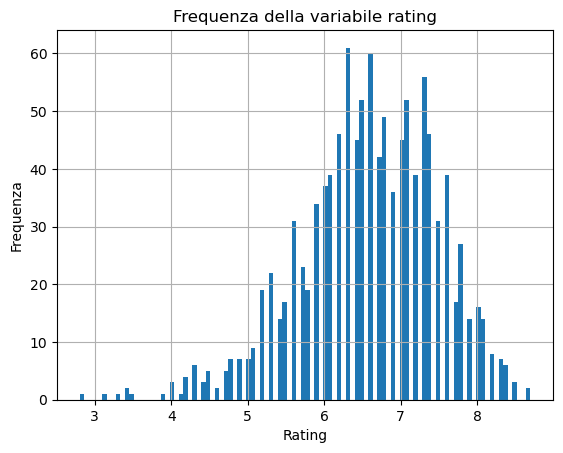

In [11]:
df['rating'].hist(bins = 100)
plt.title('Frequenza della variabile rating')
plt.xlabel('Rating')
plt.ylabel('Frequenza')
plt.show()

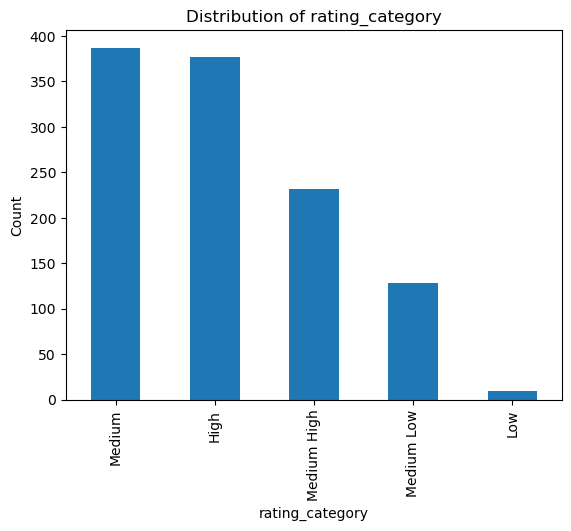

In [12]:
df['rating_category'].value_counts().plot(kind='bar')
plt.title('Distribution of rating_category')
plt.xlabel('rating_category')
plt.ylabel('Count')
plt.show()

In [13]:
df['rating_category'].value_counts()

rating_category
Medium         387
High           377
Medium High    232
Medium Low     128
Low             10
Name: count, dtype: int64

In [14]:
import ast
df["genre"] = df["genre"].apply(ast.literal_eval)

In [15]:
df['genre'].value_counts()

genre
[Animation, Adventure, Comedy]    69
[Action, Adventure, Sci-Fi]       52
[Comedy, Drama]                   45
[Horror, Mystery, Thriller]       40
[Action, Adventure, Comedy]       35
                                  ..
[Drama, History, Romance]          1
[Action, Romance, Sci-Fi]          1
[Action, Drama, Mystery]           1
[Mystery, Sci-Fi, Thriller]        1
[Documentary, Action, Mystery]     1
Name: count, Length: 184, dtype: int64

In [16]:
mlb = MultiLabelBinarizer()

genre_encoded = mlb.fit_transform(df["genre"])
column_names = [f"genre_{genre}" for genre in mlb.classes_]

df_genre_encoded = pd.DataFrame(genre_encoded, columns=column_names, index=df.index)

df = pd.concat([df, df_genre_encoded], axis=1)

df.drop(columns=["genre"], inplace=True)

In [17]:
df

,0,1,2,3,4,5,6,7,8,9,...,genre_Music,genre_Musical,genre_Mystery,genre_Romance,genre_Sci-Fi,genre_Short,genre_Sport,genre_Thriller,genre_War,genre_Western
id,,,,,,,,,,,,,,,,,,,,,
tt0062622,57057.0,65469.0,71642.0,73025.0,74060.0,49472.0,30258.0,28036.0,25824.0,32571.0,...,0,0,0,0,1,0,0,0,0,0
tt0064816,1923.0,2422.0,2853.0,2947.0,3054.0,2844.0,2617.0,1998.0,1277.0,1449.0,...,0,0,0,1,0,0,0,0,0,0
tt0088178,332925.0,302503.0,267264.0,261879.0,256608.0,196530.0,112728.0,117384.0,123024.0,119608.0,...,1,0,0,0,0,0,0,0,0,0
tt0145487,682857.0,407032.0,78058.0,81732.0,86772.0,83724.0,79940.0,39656.0,6974.0,7697.0,...,0,0,0,0,1,0,0,0,0,0
tt0359950,7813372.0,6274563.0,4781588.0,4655046.0,4535301.0,4650574.0,4758452.0,4069428.0,3471755.0,3108057.0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
tt9731534,1077363.0,1061148.0,1043451.0,912840.0,738595.0,508118.0,296236.0,318113.0,341113.0,310422.0,...,0,0,1,0,0,0,0,1,0,0
tt9735462,56775.0,57750.0,58828.0,53549.0,48484.0,37340.0,19243.0,30804.0,55897.0,40874.0,...,0,0,0,0,0,0,0,0,0,0
tt9764362,3595005.0,3401235.0,3221227.0,2645775.0,2188725.0,1681250.0,1030698.0,1138724.0,1290788.0,1204996.0,...,0,0,0,0,0,0,0,1,0,0


In [18]:
# Seleziona solo le colonne che iniziano con "genre_"
genre_cols = [col for col in df.columns if col.startswith("genre_")]

# Somma delle occorrenze dei generi
genre_counts = df[genre_cols].sum().sort_values(ascending=False)

# Genere più frequente
most_frequent_genre = genre_counts.idxmax()
most_frequent_count = genre_counts.max()

print("Conteggi per genere:")
print(genre_counts)
print(f"\nGenere più frequente: {most_frequent_genre} ({most_frequent_count} occorrenze)")

Conteggi per genere:
genre_Drama          552
genre_Comedy         408
genre_Action         359
genre_Adventure      358
genre_Thriller       160
genre_Biography      148
genre_Crime          148
genre_Horror         127
genre_Animation      119
genre_Romance        110
genre_Mystery        100
genre_Sci-Fi         100
genre_Fantasy         86
genre_Family          66
genre_History         63
genre_Music           39
genre_Documentary     27
genre_Sport           24
genre_Musical         12
genre_War             12
genre_Short            2
genre_Western          2
dtype: int64

Genere più frequente: genre_Drama (552 occorrenze)


## Preprocessing delle time series

In [19]:
df_timeseries = df.iloc[:, :100]

Controllo se ci sono valori mancanti.

In [20]:
df_timeseries.isna().sum().value_counts()

0    100
Name: count, dtype: int64

#Casting AverageRating

Poiché non ci sono valori mancanti possiamo passare a fase successiva: normalizzazione.

In [21]:
from sktime.transformations.series.outlier_detection import HampelFilter

In [22]:
import matplotlib.pyplot as plt
import pandas as pd
from sktime.transformations.series.outlier_detection import HampelFilter

# Supponiamo che il tuo DataFrame si chiami df_timeseries
# Ogni riga è un film, ogni colonna è un giorno (timestamp da 0 a 99)

# Funzione per rilevare outlier su una riga
def detect_outliers_row(row):
    hampel = HampelFilter(window_length=10, n_sigma=3, return_bool=True)
    series = pd.Series(row.values)
    outliers = hampel.fit_transform(series)
    return outliers.values

# Applica la funzione a ogni riga
outlier_matrix = df_timeseries.apply(detect_outliers_row, axis=1, result_type='expand')



C:\Users\Gagia\AppData\Local\Temp\ipykernel_7260\2845765577.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()




In [23]:
# Plot
plt.figure(figsize=(15, 8))
timestamps = df_timeseries.columns.astype(int)

for idx, row in df_timeseries.iterrows():
    revenue = row.values
    outliers = outlier_matrix.loc[idx].values

    # Linea normale
    plt.plot(timestamps, revenue, label=f'Film {idx}', alpha=0.6)

    # Outlier in rosso
    plt.scatter(timestamps[outliers], revenue[outliers], color='red', s=50, zorder=5)

plt.xlabel("Giorni")
plt.ylabel("Revenue")
plt.title("Revenue nel tempo con outlier evidenziati")
plt.legend(loc='upper right', bbox_to_anchor=(1.15, 1.0))
plt.tight_layout()
plt.grid(True)
plt.show()


C:\Users\Gagia\AppData\Local\Temp\ipykernel_7260\1010317148.py:21: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


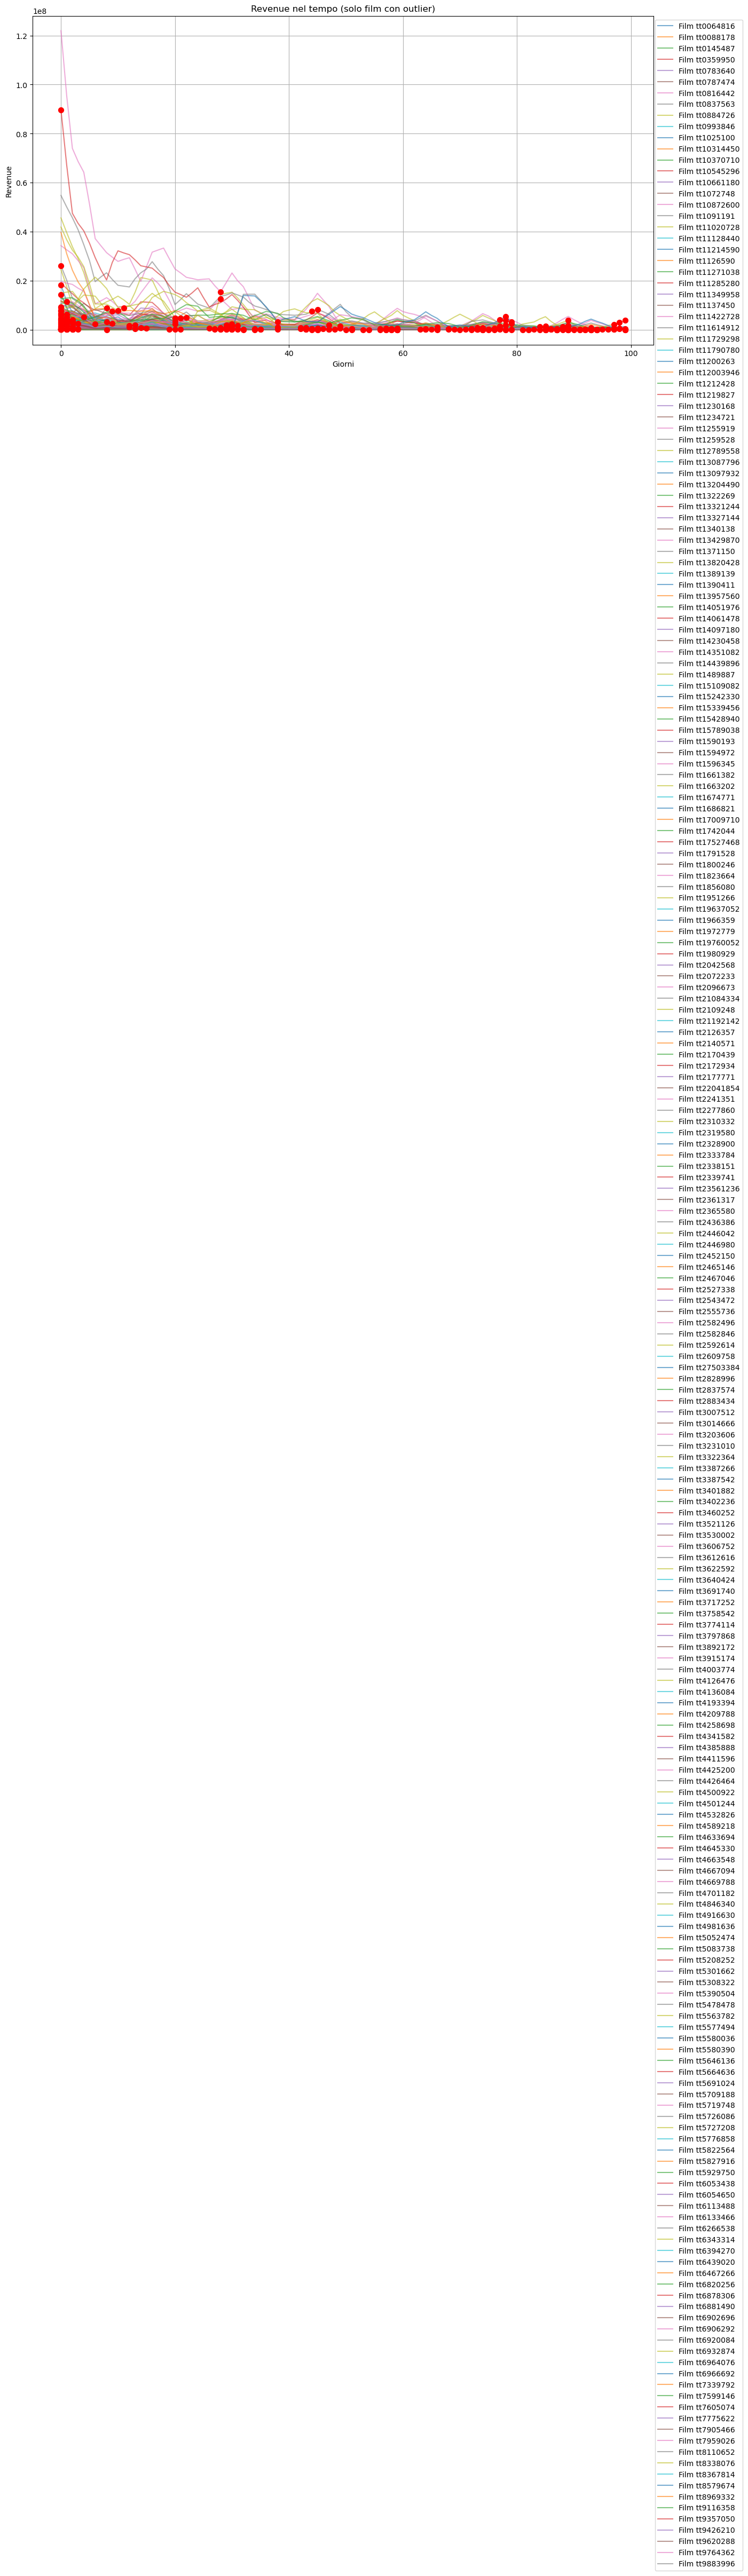

In [24]:
import matplotlib.pyplot as plt

# Trova gli ID dei film che hanno almeno un outlier
film_con_outlier = outlier_matrix[outlier_matrix.any(axis=1)].index

# Plot solo per i film filtrati
plt.figure(figsize=(15, 8))
timestamps = df_timeseries.columns.astype(int)

for idx in film_con_outlier:
    revenue = df_timeseries.loc[idx].values
    outliers = outlier_matrix.loc[idx].values

    plt.plot(timestamps, revenue, label=f'Film {idx}', alpha=0.6)
    plt.scatter(timestamps[outliers], revenue[outliers], color='red', s=50, zorder=5)

plt.xlabel("Giorni")
plt.ylabel("Revenue")
plt.title("Revenue nel tempo (solo film con outlier)")
plt.legend(loc='upper right', bbox_to_anchor=(1.15, 1.0))
plt.tight_layout()
plt.grid(True)
plt.show()


#Normalization con MinMax per poter confrontare le curve dei film

In [25]:
from sktime.transformations.series.adapt import TabularToSeriesAdaptor
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

# Adatta il MinMaxScaler per serie temporali
scaler = TabularToSeriesAdaptor(MinMaxScaler(), fit_in_transform=True)

# Funzione da applicare riga per riga
def scale_row(row):
    series = pd.Series(row.values)
    scaled = scaler.fit_transform(series)
    return scaled.values

# Applica a tutto il DataFrame
scaled_df = df_timeseries.apply(scale_row, axis=1, result_type='expand')
scaled_df.columns = df_timeseries.columns
scaled_df.index = df_timeseries.index


In [26]:
scaled_df

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
id,,,,,,,,,,,,,,,,,,,,,
tt0062622,0.744439,0.870874,0.963657,0.984444,1.000000,0.630433,0.341640,0.308243,0.274995,0.376405,...,0.096149,0.102838,0.075888,0.047812,0.052817,0.058017,0.064916,0.073288,0.092452,0.113149
tt0064816,0.435758,0.586970,0.717576,0.746061,0.778485,0.714848,0.646061,0.458485,0.240000,0.292121,...,0.457576,0.450606,0.232121,0.046061,0.075455,0.112727,0.090909,0.072424,0.069091,0.064848
tt0088178,0.855075,0.775433,0.683180,0.669083,0.655284,0.498005,0.278619,0.290808,0.305573,0.296630,...,0.026108,0.021195,0.011042,0.001267,0.002495,0.003864,0.008723,0.012859,0.007095,0.000343
tt0145487,0.844239,0.502826,0.095627,0.100174,0.106413,0.102640,0.097956,0.048093,0.007640,0.008535,...,0.034272,0.029130,0.026760,0.025117,0.012617,0.000970,0.000766,0.000464,0.000208,0.000000
tt0359950,1.000000,0.802663,0.611204,0.594976,0.579620,0.594403,0.608237,0.519877,0.443231,0.396590,...,0.003548,0.005110,0.006961,0.009380,0.006778,0.003831,0.001721,0.000000,0.000085,0.000174
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
tt9731534,1.000000,0.984922,0.968467,0.847018,0.684997,0.470688,0.273670,0.294012,0.315398,0.286860,...,0.004060,0.002235,0.001345,0.000443,0.000470,0.000503,0.000282,0.000000,0.000066,0.000122
tt9735462,0.965079,0.981664,1.000000,0.910206,0.824052,0.634496,0.326671,0.523320,0.950145,0.694608,...,0.021177,0.021687,0.016806,0.011924,0.009866,0.007654,0.010172,0.014373,0.014730,0.015003
tt9764362,1.000000,0.944371,0.892693,0.727487,0.596273,0.450583,0.263817,0.294830,0.338486,0.313856,...,0.067706,0.093487,0.081620,0.067032,0.041809,0.020420,0.015375,0.009291,0.004666,0.000000


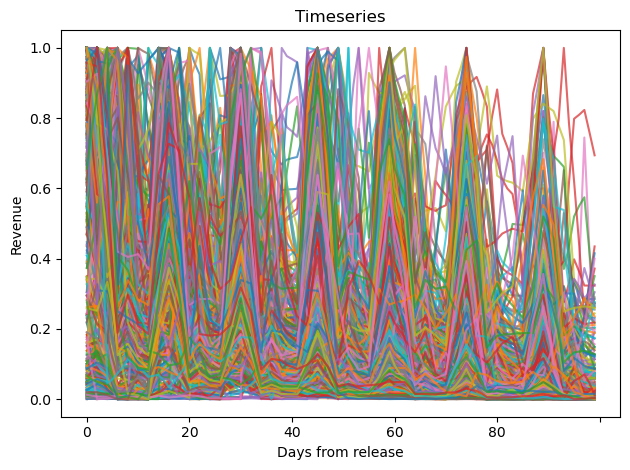

In [27]:
# Per osservare le time series necessario considerare solo valori numerici
scaled_df.iloc[:, :100].T.plot(legend=False, alpha=0.7)
plt.title('Timeseries')
plt.xlabel('Days from release')
plt.ylabel('Revenue')
plt.tight_layout()
plt.show()

#Confronto Outliers

In [28]:
import numpy as np
import pandas as pd
from sktime.transformations.series.outlier_detection import HampelFilter

# Funzione parametrica
def detect_outliers_row(row, window_length=3, n_sigma=3):
    hampel = HampelFilter(window_length=window_length, n_sigma=n_sigma, return_bool=True)
    series = pd.Series(row.values)
    outliers = hampel.fit_transform(series)
    return outliers.values

# Applica il rilevamento agli interi dataframe
def detect_outliers_df(df, window_length=3, n_sigma=3):
    return df.apply(lambda row: detect_outliers_row(row, window_length, n_sigma),
                    axis=1, result_type="expand").astype(bool)

# Esempio: parametri diversi per i due dataset
outliers_df1 = detect_outliers_df(df_timeseries, window_length=7, n_sigma=3)
outliers_df2 = detect_outliers_df(scaled_df, window_length=7, n_sigma=3)

# Outlier comuni (True se entrambi hanno outlier nello stesso punto)
common_outliers = outliers_df1 & outliers_df2

# Conteggi
n_common = common_outliers.sum().sum()
n_outliers_df1 = outliers_df1.sum().sum()
n_outliers_df2 = outliers_df2.sum().sum()
n_total_cells = common_outliers.size

# Percentuali
perc_common_over_total = n_common / n_total_cells * 100
perc_common_over_min = n_common / min(n_outliers_df1, n_outliers_df2) * 100 if min(n_outliers_df1, n_outliers_df2) > 0 else 0

print(f"Outlier in comune: {n_common}")
print(f"Outlier dataset1: {n_outliers_df1}")
print(f"Outlier dataset2: {n_outliers_df2}")
print(f"Percentuale sul totale delle celle: {perc_common_over_total:.2f}%")
print(f"Percentuale rispetto al dataset con meno outlier: {perc_common_over_min:.2f}%")


Outlier in comune: 597
Outlier dataset1: 597
Outlier dataset2: 597
Percentuale sul totale delle celle: 0.53%
Percentuale rispetto al dataset con meno outlier: 100.00%


#Sostituzione Anomalies